
# 11 — All Figures Output: EES Framework Validation (Version 3)

**Purpose:** Generate dissertation-ready figures corresponding to the Chapter 4 result tables, while preserving the dissertation's domain-by-domain reporting structure.

## Design principle

- One empirical result → one clearly interpretable figure.
- Credit Risk, Healthcare, and Criminal Justice remain separate where the dissertation discusses them separately.
- Summary figures are created only where Chapter 4 synthesises evidence across domains.
- Figures are exported as high-resolution PNG and vector PDF/SVG files.
- The notebook does **not** delete the source tables. It creates visual alternatives so the final dissertation can retain compact tables where exact values are essential and use figures where patterns, rankings, and contrasts are more important.

## Expected input

This notebook reads the CSV outputs created by Notebook 09 from:

`07_Results/09_cross_dataset_framework_validation/tables`

It follows the same folder logic as Notebook 10.


**Version 2 fix:** corrected filename slug generation and added the missing regular-expression import.

**Version 3 refinements**
- Removed Accuracy from the BPS-focused predictive-performance figures.
- Baseline figures now display only Recall, ROC-AUC, Precision, and BPS.
- Applied dissertation-approved model abbreviations throughout all figure labels: LR, DT, RF, XGB, and MLP.


In [1]:

# ============================================================
# 11 All Figures Output — EES Framework Validation
# Configurable Google Colab version
# ============================================================

from pathlib import Path
import warnings
import re
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

try:
    from IPython.display import display, Markdown
except Exception:
    display = print
    Markdown = lambda x: x

# ============================================================
# 1. CONFIGURATION
# ============================================================

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        ROOT_PATH = Path("/content/drive/MyDrive/Master_Research")
    except Exception as exc:
        print("Google Drive mount skipped:", exc)
        ROOT_PATH = Path(".")
else:
    ROOT_PATH = Path(".")

RESULTS_ROOT = ROOT_PATH / "07_Results"
INPUT_TABLES_PATH = RESULTS_ROOT / "09_cross_dataset_framework_validation" / "tables"
OUTPUT_ROOT = RESULTS_ROOT / "11_all_figures_output_framework_validation"
FIGURES_PATH = OUTPUT_ROOT / "publication_outputs" / "figures"
MANIFEST_PATH = OUTPUT_ROOT / "publication_outputs" / "figure_manifest.csv"

FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# Output options
SAVE_PNG = True
SAVE_PDF = True
SAVE_SVG = True
SHOW_FIGURES = True

# Figure behaviour
DPI = 600
ROUND_DECIMALS = 3
MODEL_ORDER = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "MLP",
]

# Dissertation-approved model abbreviations used in ALL figure labels.
MODEL_ABBREVIATIONS = {
    "Logistic Regression": "LR",
    "Decision Tree": "DT",
    "Random Forest": "RF",
    "XGBoost": "XGB",
    "Extreme Gradient Boosting": "XGB",
    "Multi-Layer Perceptron": "MLP",
    "Multilayer Perceptron": "MLP",
    "MLP": "MLP",
}
DOMAIN_ORDER = [
    "Credit Risk",
    "Healthcare",
    "Criminal Justice",
]

# Use exact dissertation terminology.
DIMENSION_LABELS = {
    "fidelity_score": "Fidelity",
    "stability_score": "Stability",
    "actionability_score": "Counterfactual Actionability",
    "regulatory_alignment_score": "Regulatory Alignment",
}

# Neutral academic style. Matplotlib defaults determine colours.
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": DPI,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.linewidth": 0.8,
})

print("Input folder :", INPUT_TABLES_PATH)
print("Output folder:", FIGURES_PATH)


Mounted at /content/drive
Input folder : /content/drive/MyDrive/Master_Research/07_Results/09_cross_dataset_framework_validation/tables
Output folder: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures


In [2]:

# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

FIGURE_MANIFEST = []

def clean_columns(df):
    out = df.copy()
    out.columns = (
        out.columns.astype(str)
        .str.strip()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
        .str.replace("/", "_", regex=False)
        .str.lower()
    )
    return out

def read_table(filename, required=True):
    path = INPUT_TABLES_PATH / filename
    if not path.exists():
        message = f"Missing input table: {path}"
        if required:
            raise FileNotFoundError(message)
        print(message)
        return pd.DataFrame()
    return clean_columns(pd.read_csv(path))

def find_first_column(df, candidates):
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    return None

def require_columns(df, columns, table_name):
    missing = [c for c in columns if c not in df.columns]
    if missing:
        raise KeyError(
            f"{table_name} is missing required columns: {missing}\n"
            f"Available columns: {list(df.columns)}"
        )

def normalise_domain_labels(df):
    out = df.copy()
    domain_col = find_first_column(
        out,
        ["dataset_label", "validation_domain", "domain", "dataset_name"]
    )
    if domain_col is None:
        return out

    mapping = {
        "german credit": "Credit Risk",
        "german_credit": "Credit Risk",
        "credit risk": "Credit Risk",
        "credit_risk": "Credit Risk",
        "pima indians diabetes": "Healthcare",
        "pima diabetes": "Healthcare",
        "pima_diabetes": "Healthcare",
        "healthcare": "Healthcare",
        "compas": "Criminal Justice",
        "criminal justice": "Criminal Justice",
        "criminal_justice": "Criminal Justice",
    }

    def map_value(value):
        key = str(value).strip().lower()
        return mapping.get(key, str(value).strip())

    out["dataset_label"] = out[domain_col].map(map_value)
    return out

def normalise_model_labels(df):
    out = df.copy()
    model_col = find_first_column(out, ["model_name", "model", "algorithm"])
    if model_col is None:
        return out

    mapping = {
        "logistic_regression": "Logistic Regression",
        "logistic regression": "Logistic Regression",
        "decision_tree": "Decision Tree",
        "decision tree": "Decision Tree",
        "random_forest": "Random Forest",
        "random forest": "Random Forest",
        "xgboost": "XGBoost",
        "xgb": "XGBoost",
        "extreme gradient boosting": "XGBoost",
        "extreme_gradient_boosting": "XGBoost",
        "mlp": "MLP",
        "multi-layer perceptron": "MLP",
        "multi_layer_perceptron": "MLP",
        "multilayer perceptron": "MLP",
    }

    out["model_name"] = out[model_col].map(
        lambda x: mapping.get(str(x).strip().lower(), str(x).strip())
    )
    return out

def prepare_df(df):
    return normalise_model_labels(normalise_domain_labels(df))

def ordered_models(values):
    present = list(dict.fromkeys([str(v) for v in values]))
    return [m for m in MODEL_ORDER if m in present] + [m for m in present if m not in MODEL_ORDER]

def ordered_domains(values):
    present = list(dict.fromkeys([str(v) for v in values]))
    return [d for d in DOMAIN_ORDER if d in present] + [d for d in present if d not in DOMAIN_ORDER]

def abbreviate_model_name(value):
    """
    Return the dissertation-approved abbreviation for a model name.
    Unknown labels are returned unchanged.
    """
    text = str(value).strip()
    return MODEL_ABBREVIATIONS.get(text, text)

def abbreviate_model_labels(values):
    """Apply dissertation-approved model abbreviations to an iterable."""
    return [abbreviate_model_name(v) for v in values]

def style_axes(ax, grid_axis="y"):
    ax.grid(axis=grid_axis, alpha=0.25, linewidth=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def add_value_labels(ax, decimals=3, horizontal=False, padding=3, fontsize=8):
    for container in ax.containers:
        values = getattr(container, "datavalues", [])
        labels = []
        for value in values:
            if value is None or pd.isna(value):
                labels.append("")
            else:
                labels.append(f"{float(value):.{decimals}f}")
        try:
            ax.bar_label(
                container,
                labels=labels,
                padding=padding,
                fontsize=fontsize,
                label_type="edge",
            )
        except Exception:
            pass

def add_rank_labels(ax, ranks, x_positions, y_values):
    for x, y, rank in zip(x_positions, y_values, ranks):
        if pd.notna(rank):
            ax.annotate(
                f"Rank {int(rank)}",
                (x, y),
                xytext=(0, 16),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
            )

def save_figure(fig, stem, chapter_table=None, caption=None):
    saved = []
    if SAVE_PNG:
        path = FIGURES_PATH / f"{stem}.png"
        fig.savefig(path, dpi=DPI, bbox_inches="tight")
        saved.append(path)
    if SAVE_PDF:
        path = FIGURES_PATH / f"{stem}.pdf"
        fig.savefig(path, bbox_inches="tight")
        saved.append(path)
    if SAVE_SVG:
        path = FIGURES_PATH / f"{stem}.svg"
        fig.savefig(path, bbox_inches="tight")
        saved.append(path)

    FIGURE_MANIFEST.append({
        "figure_file_stem": stem,
        "corresponding_dissertation_table": chapter_table or "",
        "suggested_caption": caption or "",
        "saved_formats": ", ".join(p.suffix.replace(".", "").upper() for p in saved),
    })

    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)
    print("Saved:", ", ".join(str(p) for p in saved))
    return saved

def domain_subset(df, domain):
    require_columns(df, ["dataset_label", "model_name"], "Domain result table")
    sub = df[df["dataset_label"] == domain].copy()
    if sub.empty:
        print(f"No rows found for domain: {domain}")
    return sub

def score_axis(ax, upper=1.0):
    ax.set_ylim(0, upper)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))

def wrap_labels(labels, width=18):
    import textwrap
    return ["\n".join(textwrap.wrap(str(label), width=width)) for label in labels]

def plot_single_score_by_domain(
    df,
    domain,
    score_col,
    rank_col,
    title,
    ylabel,
    stem,
    chapter_table,
    caption,
    upper=1.05,
):
    sub = domain_subset(df, domain)
    if sub.empty or score_col not in sub.columns:
        return

    if rank_col in sub.columns:
        sub = sub.sort_values(rank_col)
    else:
        sub = sub.sort_values(score_col, ascending=False)

    models = abbreviate_model_labels(sub["model_name"].tolist())
    values = pd.to_numeric(sub[score_col], errors="coerce").tolist()
    x = np.arange(len(models))

    fig, ax = plt.subplots(figsize=(8.6, 5.2))
    ax.bar(x, values)
    ax.set_xticks(x)
    ax.set_xticklabels(wrap_labels(models, 15))
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Candidate ML Model")
    ax.set_title(title, pad=12)
    ax.set_ylim(0, upper)
    style_axes(ax)
    add_value_labels(ax, decimals=3)

    if rank_col in sub.columns:
        add_rank_labels(ax, sub[rank_col].tolist(), x, values)

    fig.tight_layout()
    save_figure(fig, stem, chapter_table, caption)

def plot_grouped_components_by_domain(
    df,
    domain,
    component_cols,
    title,
    ylabel,
    stem,
    chapter_table,
    caption,
    rank_col=None,
    upper=1.05,
):
    sub = domain_subset(df, domain)
    available = [c for c in component_cols if c in sub.columns]
    if sub.empty or not available:
        return

    if rank_col and rank_col in sub.columns:
        sub = sub.sort_values(rank_col)
    else:
        ordering_col = available[-1]
        sub = sub.sort_values(ordering_col, ascending=False)

    models = abbreviate_model_labels(sub["model_name"].tolist())
    x = np.arange(len(models))
    width = 0.8 / len(available)

    fig, ax = plt.subplots(figsize=(10.6, 5.8))
    for idx, col in enumerate(available):
        values = pd.to_numeric(sub[col], errors="coerce").values
        offset = (idx - (len(available) - 1) / 2) * width
        label = DIMENSION_LABELS.get(
            col,
            col.replace("_score", "").replace("_", " ").title()
        )
        ax.bar(x + offset, values, width=width, label=label)

    ax.set_xticks(x)
    ax.set_xticklabels(wrap_labels(models, 15))
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Candidate ML Model")
    ax.set_title(title, pad=12)
    ax.set_ylim(0, upper)
    style_axes(ax)
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.16),
        ncol=min(4, len(available)),
        frameon=False,
    )
    add_value_labels(ax, decimals=3, fontsize=7)
    fig.tight_layout()
    save_figure(fig, stem, chapter_table, caption)

def plot_heatmap(
    matrix_df,
    title,
    stem,
    chapter_table,
    caption,
    value_format=".3f",
    figsize=(9.5, 5.6),
    xlabel="",
    ylabel="",
):
    if matrix_df.empty:
        return

    data = matrix_df.astype(float)
    fig, ax = plt.subplots(figsize=figsize)
    image = ax.imshow(data.values, aspect="auto", vmin=np.nanmin(data.values), vmax=np.nanmax(data.values))

    ax.set_xticks(np.arange(len(data.columns)))
    ax.set_xticklabels(wrap_labels(data.columns, 16), rotation=30, ha="right")
    ax.set_yticks(np.arange(len(data.index)))
    ax.set_yticklabels(abbreviate_model_labels(data.index))
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, pad=12)

    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            value = data.iloc[i, j]
            if pd.notna(value):
                ax.text(j, i, format(value, value_format), ha="center", va="center", fontsize=8)

    cbar = fig.colorbar(image, ax=ax)
    cbar.ax.set_ylabel("Score", rotation=270, labelpad=15)
    fig.tight_layout()
    save_figure(fig, stem, chapter_table, caption)

def safe_slug(text):
    """
    Convert text into a filesystem-safe identifier.
    Example: "Credit Risk" -> "Credit_Risk"
    """
    text = str(text).strip()
    cleaned = []
    previous_was_underscore = False

    for char in text:
        if char.isalnum():
            cleaned.append(char)
            previous_was_underscore = False
        else:
            if not previous_was_underscore:
                cleaned.append("_")
                previous_was_underscore = True

    return "".join(cleaned).strip("_")


In [3]:

# ============================================================
# 3. LOAD NOTEBOOK 09 OUTPUT TABLES
# ============================================================

dataset_overview_df = prepare_df(read_table("dataset_overview.csv", required=False))
baseline_df = prepare_df(read_table("baseline_component_comparison.csv"))
fidelity_df = prepare_df(read_table("fidelity_component_comparison.csv"))
stability_df = prepare_df(read_table("stability_component_comparison.csv"))
actionability_df = prepare_df(read_table("actionability_component_comparison.csv"))
regulatory_df = prepare_df(read_table("regulatory_component_comparison.csv"))
ees_df = prepare_df(read_table("ees_component_comparison.csv"))
average_ees_df = prepare_df(read_table("cross_dataset_average_ees.csv", required=False))
ahp_df = prepare_df(read_table("ahp_scheme_summary.csv", required=False))
robustness_df = prepare_df(read_table("ranking_robustness_comparison.csv", required=False))
winner_matrix_df = clean_columns(read_table("cross_dataset_winner_matrix.csv", required=False))

print("Loaded source tables successfully.")
print("Domains:", ordered_domains(baseline_df["dataset_label"].dropna().unique()))
print("Models :", ordered_models(baseline_df["model_name"].dropna().unique()))


Loaded source tables successfully.
Domains: ['Credit Risk', 'Healthcare', 'Criminal Justice']
Models : ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'MLP']



## Figure group A — Baseline predictive performance

These figures provide visual alternatives for Tables 4.1–4.4.  
Each validation domain receives a separate figure, preserving the narrative structure of Sections 4.2.2–4.2.4. The figures focus specifically on the three BPS constituent metrics—Recall, ROC-AUC, and Precision—together with the resulting BPS. Accuracy and F1-score remain reported in the detailed tables but are intentionally excluded from these BPS-focused figures. A cross-domain champion figure supports Section 4.2.5.


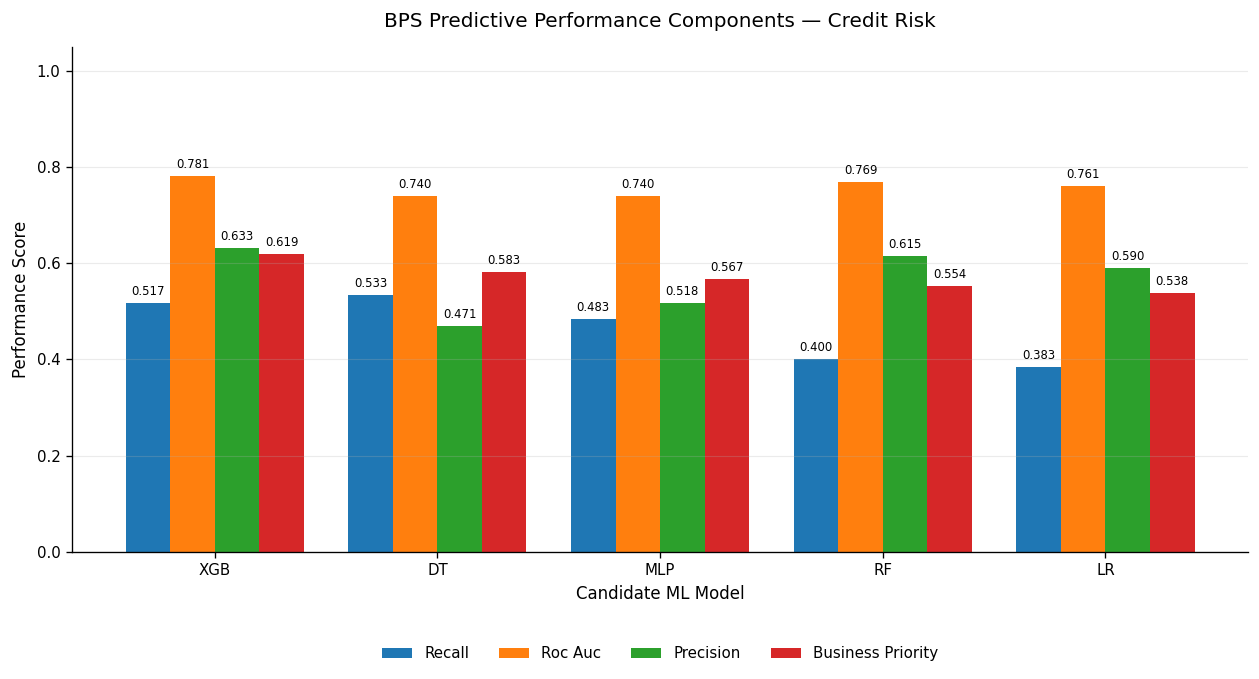

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Credit_Risk_Baseline_Predictive_Performance.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Credit_Risk_Baseline_Predictive_Performance.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Credit_Risk_Baseline_Predictive_Performance.svg


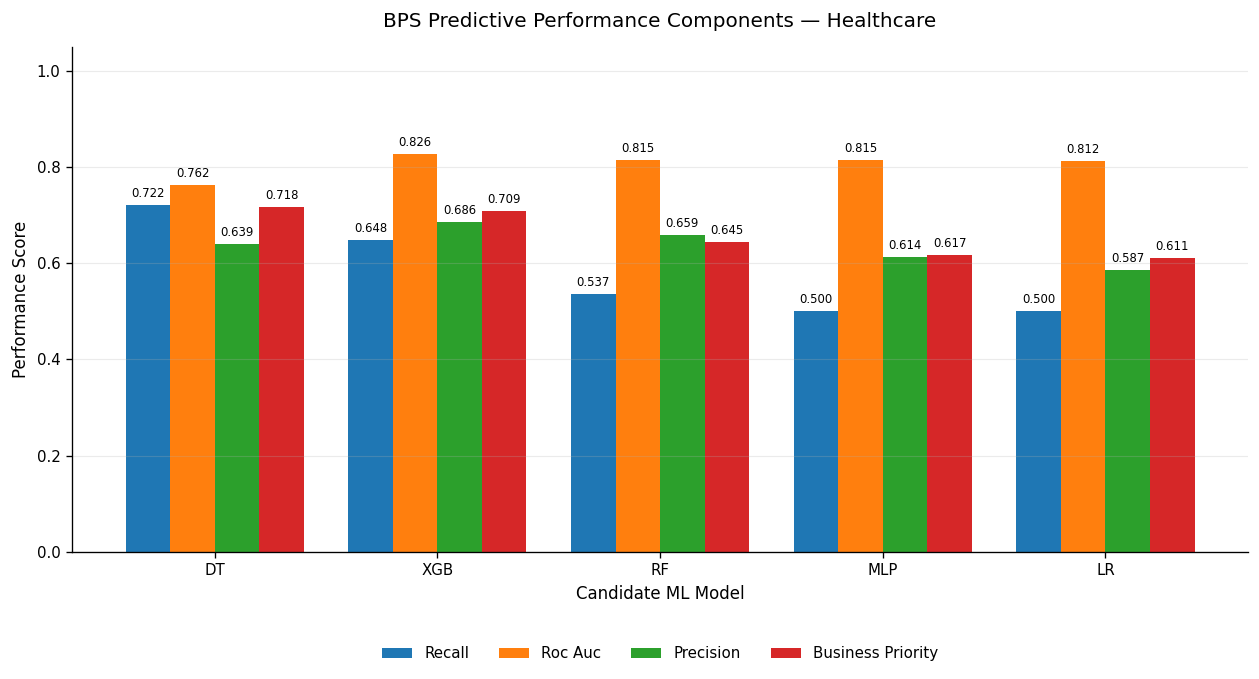

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Healthcare_Baseline_Predictive_Performance.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Healthcare_Baseline_Predictive_Performance.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Healthcare_Baseline_Predictive_Performance.svg


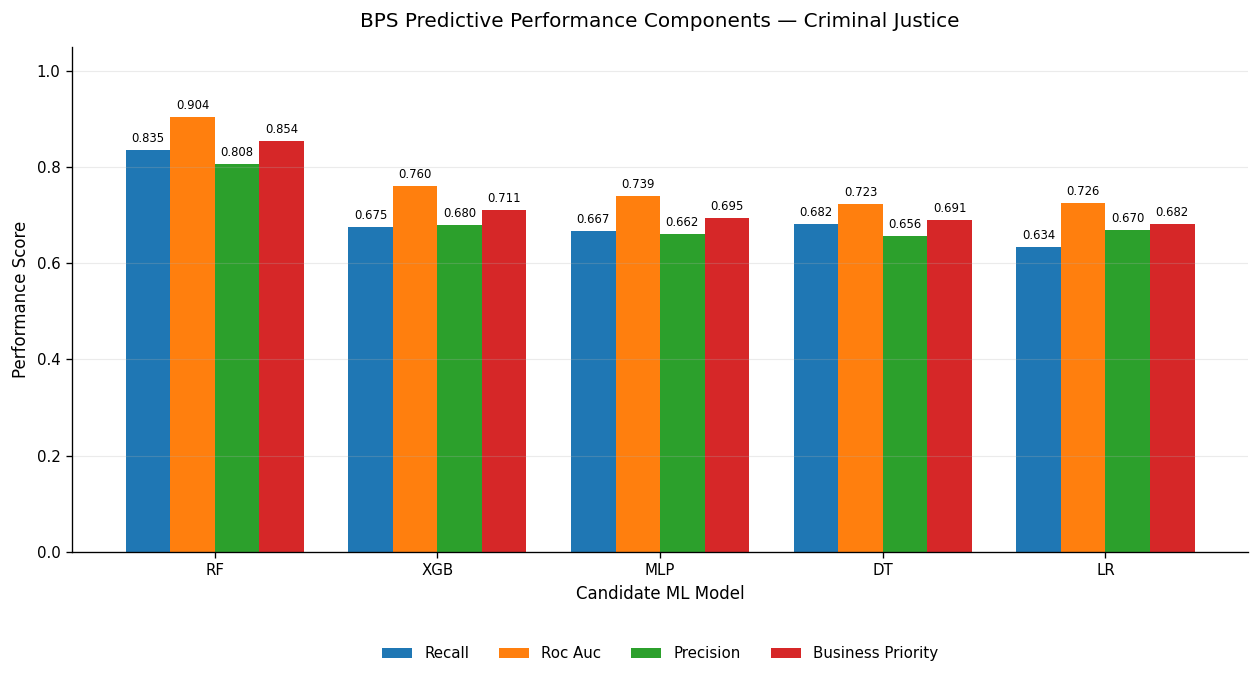

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Criminal_Justice_Baseline_Predictive_Performance.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Criminal_Justice_Baseline_Predictive_Performance.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Criminal_Justice_Baseline_Predictive_Performance.svg


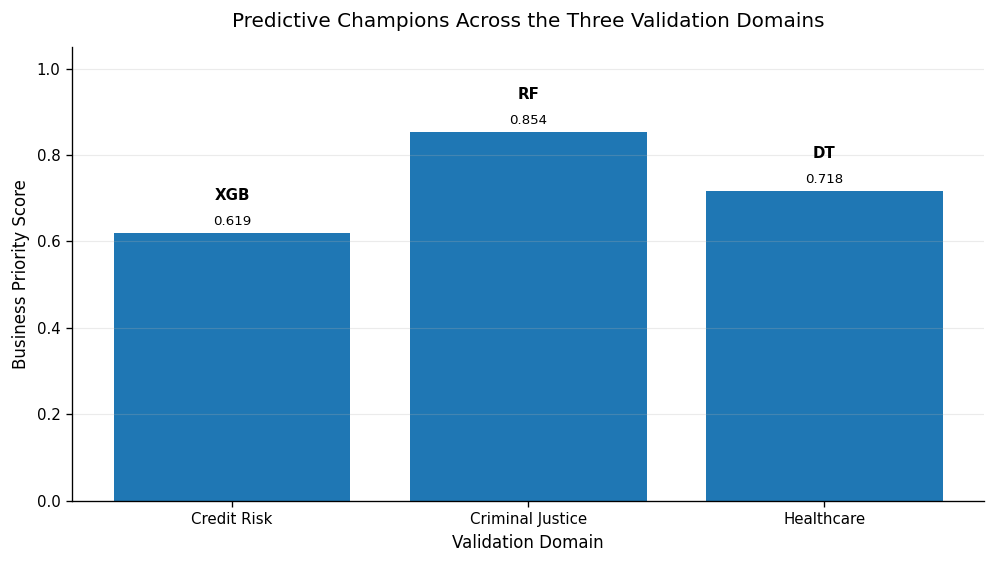

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Summary_Predictive_Champions.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Summary_Predictive_Champions.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Summary_Predictive_Champions.svg


[PosixPath('/content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Summary_Predictive_Champions.png'),
 PosixPath('/content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Summary_Predictive_Champions.pdf'),
 PosixPath('/content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_A_Summary_Predictive_Champions.svg')]

In [4]:

# ============================================================
# 4. BASELINE PREDICTIVE PERFORMANCE FIGURES
# Tables 4.1–4.4
# ============================================================

baseline_metrics = [
    c for c in ["recall", "roc_auc", "precision", "business_priority_score"]
    if c in baseline_df.columns
]

baseline_rank_col = find_first_column(
    baseline_df,
    ["business_priority_rank", "baseline_rank", "rank"]
)

table_map = {
    "Credit Risk": "Table 4.1",
    "Healthcare": "Table 4.2",
    "Criminal Justice": "Table 4.3",
}

for domain in ordered_domains(baseline_df["dataset_label"].dropna().unique()):
    plot_grouped_components_by_domain(
        baseline_df,
        domain,
        baseline_metrics,
        title=f"BPS Predictive Performance Components — {domain}",
        ylabel="Performance Score",
        stem=f"Figure_A_{safe_slug(domain)}_Baseline_Predictive_Performance",
        chapter_table=table_map.get(domain, ""),
        caption=f"Recall, ROC-AUC, Precision, and the resulting BPS across candidate ML models for the {domain} validation domain.",
        rank_col=baseline_rank_col,
        upper=1.05,
    )

# Cross-domain predictive champions
if baseline_rank_col:
    champions = (
        baseline_df.sort_values(["dataset_label", baseline_rank_col])
        .groupby("dataset_label", as_index=False)
        .first()
    )
else:
    champions = (
        baseline_df.sort_values(["dataset_label", "business_priority_score"], ascending=[True, False])
        .groupby("dataset_label", as_index=False)
        .first()
    )

fig, ax = plt.subplots(figsize=(8.4, 4.8))
x = np.arange(len(champions))
values = champions["business_priority_score"].astype(float).values
bars = ax.bar(x, values)
ax.set_xticks(x)
ax.set_xticklabels(champions["dataset_label"])
ax.set_ylabel("Business Priority Score")
ax.set_xlabel("Validation Domain")
ax.set_title("Predictive Champions Across the Three Validation Domains", pad=12)
ax.set_ylim(0, 1.05)
style_axes(ax)
add_value_labels(ax, decimals=3)

for index, row in champions.reset_index(drop=True).iterrows():
    ax.annotate(
        abbreviate_model_name(row["model_name"]),
        (index, float(row["business_priority_score"])),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

fig.tight_layout()
save_figure(
    fig,
    "Figure_A_Summary_Predictive_Champions",
    "Table 4.4",
    "Summary of BPS predictive champions across the three validation domains.",
)



## Figure group B — Fidelity dimension

These figures provide visual alternatives for Tables 4.5–4.7.  
Each chart retains the component structure of the Fidelity dimension: SHAP Reconstruction Fidelity, LIME Fidelity, SHAP–LIME Agreement, and the resulting Fidelity Score.


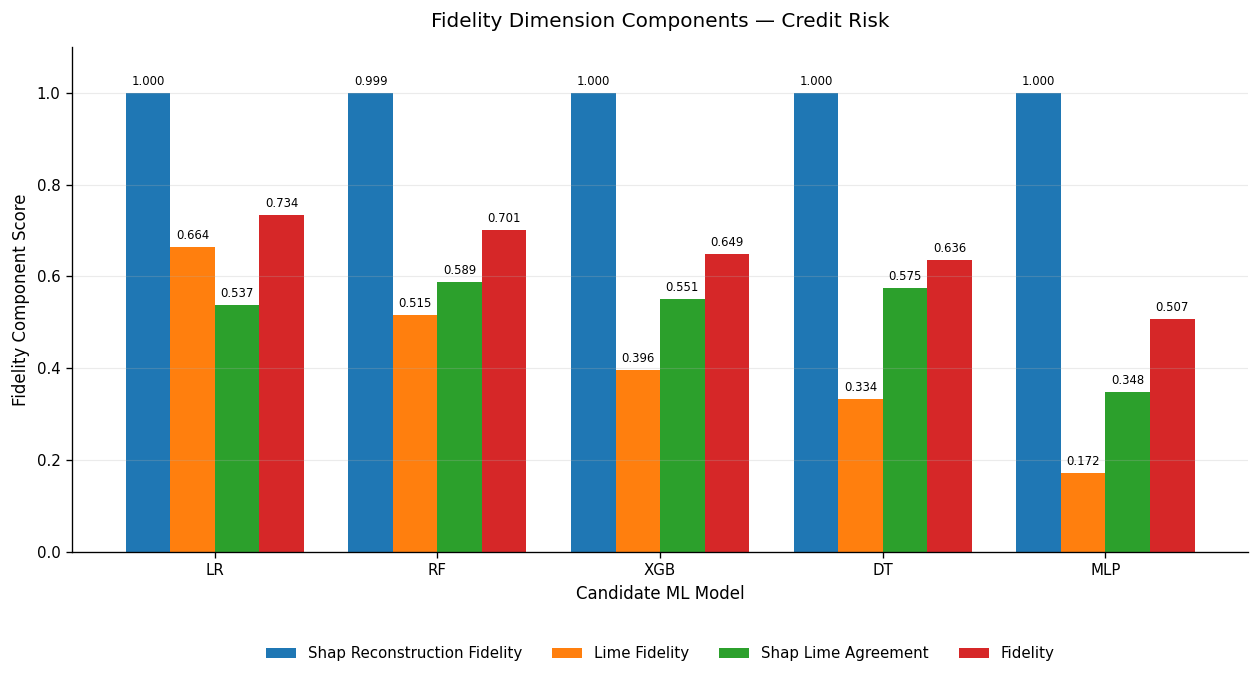

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Credit_Risk_Fidelity_Dimension.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Credit_Risk_Fidelity_Dimension.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Credit_Risk_Fidelity_Dimension.svg


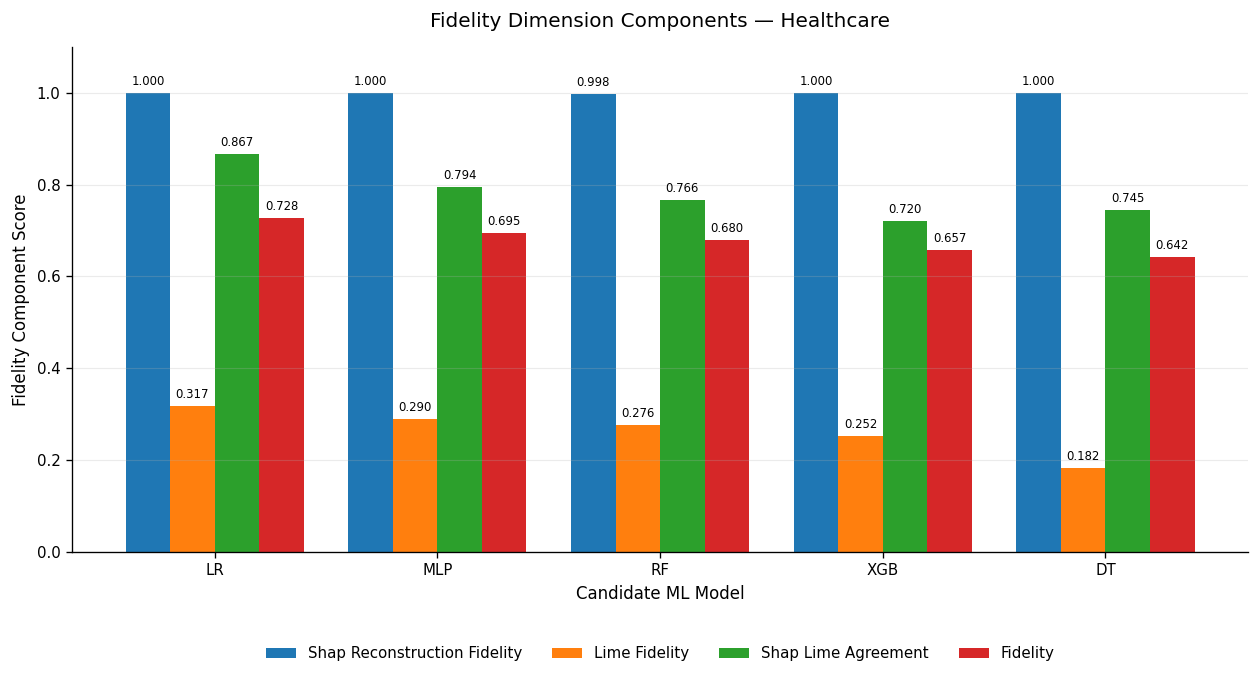

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Healthcare_Fidelity_Dimension.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Healthcare_Fidelity_Dimension.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Healthcare_Fidelity_Dimension.svg


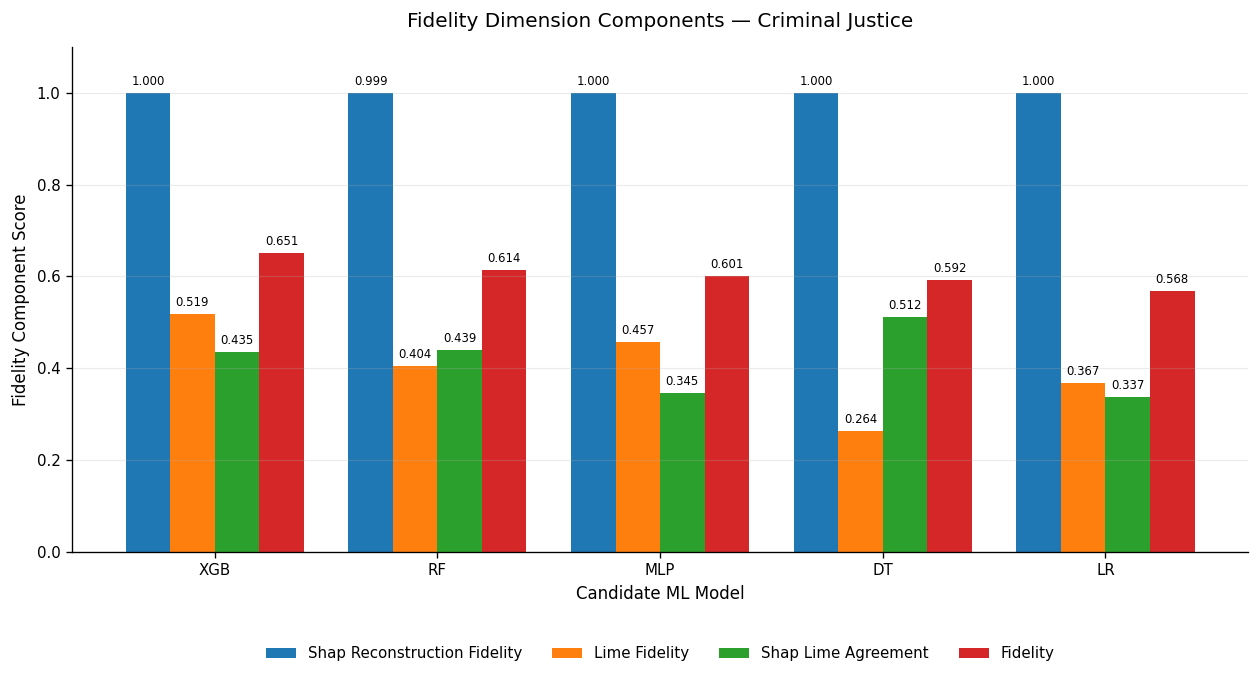

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Criminal_Justice_Fidelity_Dimension.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Criminal_Justice_Fidelity_Dimension.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_B_Criminal_Justice_Fidelity_Dimension.svg


In [5]:

# ============================================================
# 5. FIDELITY FIGURES
# Tables 4.5–4.7
# ============================================================

fidelity_components = [
    c for c in [
        "shap_reconstruction_fidelity_score",
        "lime_fidelity_score",
        "shap_lime_agreement_score",
        "fidelity_score",
    ]
    if c in fidelity_df.columns
]
fidelity_rank_col = find_first_column(fidelity_df, ["fidelity_rank", "rank"])

table_map = {
    "Credit Risk": "Table 4.5",
    "Healthcare": "Table 4.6",
    "Criminal Justice": "Table 4.7",
}

for domain in ordered_domains(fidelity_df["dataset_label"].dropna().unique()):
    plot_grouped_components_by_domain(
        fidelity_df,
        domain,
        fidelity_components,
        title=f"Fidelity Dimension Components — {domain}",
        ylabel="Fidelity Component Score",
        stem=f"Figure_B_{safe_slug(domain)}_Fidelity_Dimension",
        chapter_table=table_map.get(domain, ""),
        caption=f"Fidelity dimension components for the {domain} validation domain.",
        rank_col=fidelity_rank_col,
        upper=1.10,
    )



## Figure group C — Stability dimension

These figures provide visual alternatives for Tables 4.8–4.10.  
The bars show the normalised Stability Score, while the Mean Local Lipschitz Ratio is annotated to retain the underlying robustness evidence.


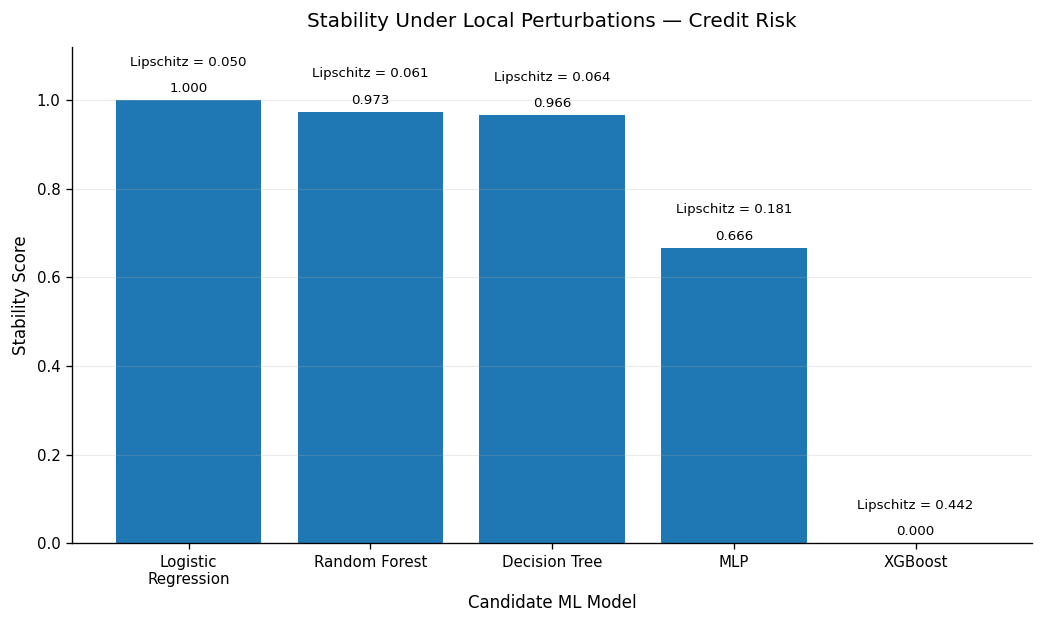

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Credit_Risk_Stability_Dimension.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Credit_Risk_Stability_Dimension.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Credit_Risk_Stability_Dimension.svg


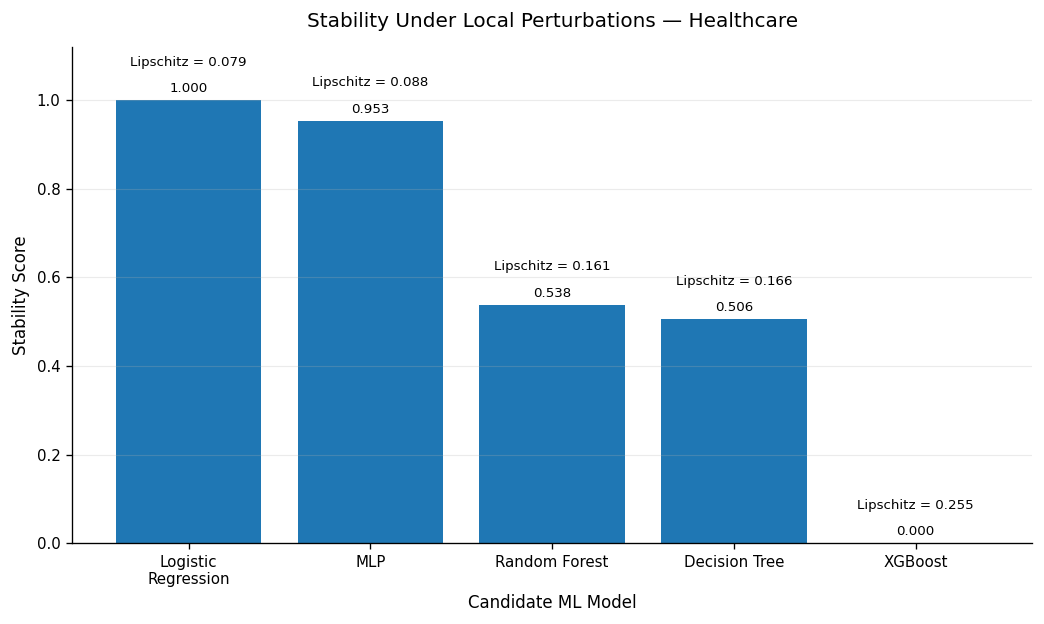

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Healthcare_Stability_Dimension.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Healthcare_Stability_Dimension.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Healthcare_Stability_Dimension.svg


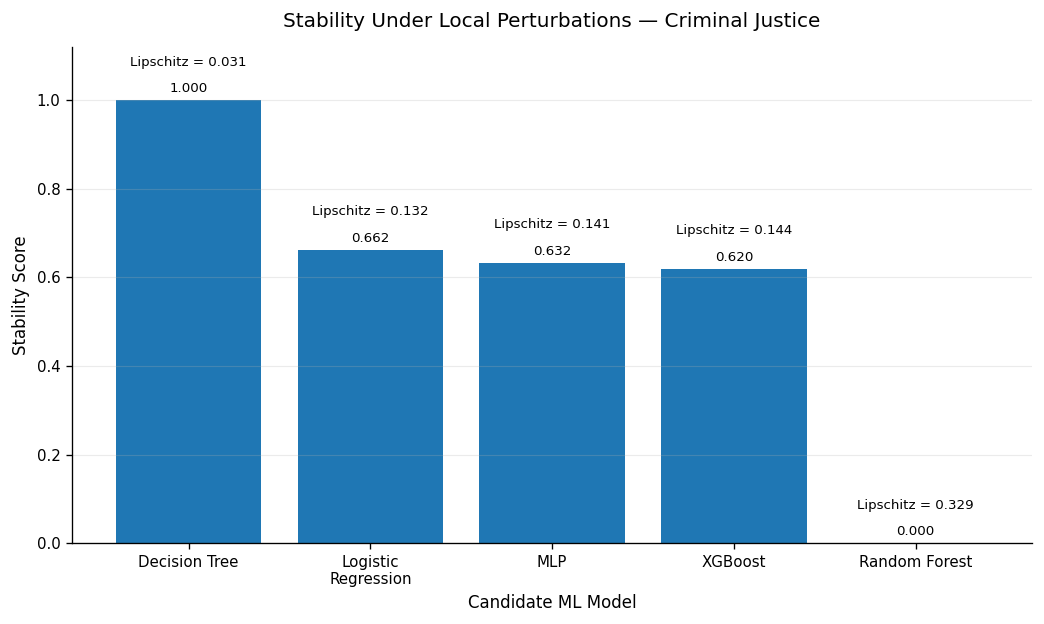

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Criminal_Justice_Stability_Dimension.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Criminal_Justice_Stability_Dimension.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_C_Criminal_Justice_Stability_Dimension.svg


In [6]:

# ============================================================
# 6. STABILITY FIGURES
# Tables 4.8–4.10
# ============================================================

stability_rank_col = find_first_column(stability_df, ["stability_rank", "rank"])

table_map = {
    "Credit Risk": "Table 4.8",
    "Healthcare": "Table 4.9",
    "Criminal Justice": "Table 4.10",
}

for domain in ordered_domains(stability_df["dataset_label"].dropna().unique()):
    sub = domain_subset(stability_df, domain)
    if sub.empty:
        continue

    if stability_rank_col and stability_rank_col in sub.columns:
        sub = sub.sort_values(stability_rank_col)
    else:
        sub = sub.sort_values("stability_score", ascending=False)

    x = np.arange(len(sub))
    values = sub["stability_score"].astype(float).values

    fig, ax = plt.subplots(figsize=(8.8, 5.3))
    ax.bar(x, values)
    ax.set_xticks(x)
    ax.set_xticklabels(wrap_labels(sub["model_name"], 15))
    ax.set_ylabel("Stability Score")
    ax.set_xlabel("Candidate ML Model")
    ax.set_title(f"Stability Under Local Perturbations — {domain}", pad=12)
    ax.set_ylim(0, 1.12)
    style_axes(ax)
    add_value_labels(ax, decimals=3)

    if "mean_local_lipschitz_ratio" in sub.columns:
        for idx, (_, row) in enumerate(sub.iterrows()):
            ax.annotate(
                f"Lipschitz = {row['mean_local_lipschitz_ratio']:.3f}",
                (idx, float(row["stability_score"])),
                xytext=(0, 19),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
            )

    fig.tight_layout()
    save_figure(
        fig,
        f"Figure_C_{safe_slug(domain)}_Stability_Dimension",
        table_map.get(domain, ""),
        f"Stability dimension results for the {domain} validation domain.",
    )



## Figure group D — Counterfactual Actionability dimension

These figures provide visual alternatives for Tables 4.11–4.13.  
They preserve Availability, Proximity, Sparsity, and the composite Actionability Score.


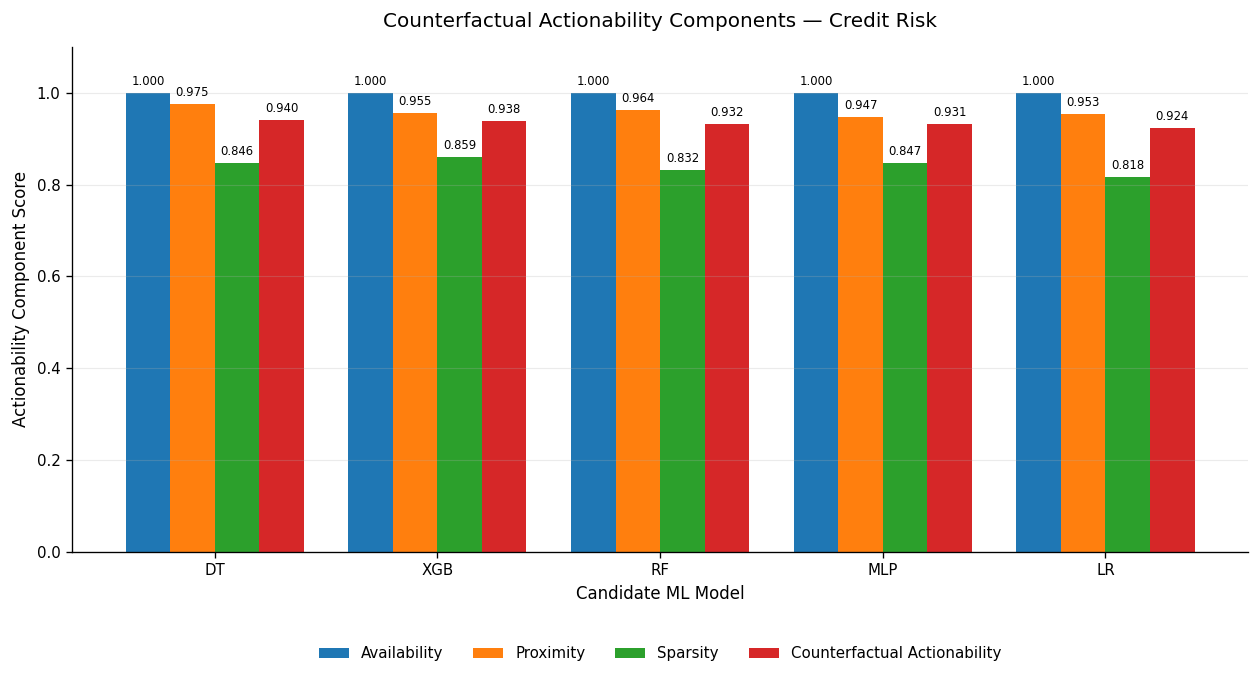

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Credit_Risk_Counterfactual_Actionability.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Credit_Risk_Counterfactual_Actionability.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Credit_Risk_Counterfactual_Actionability.svg


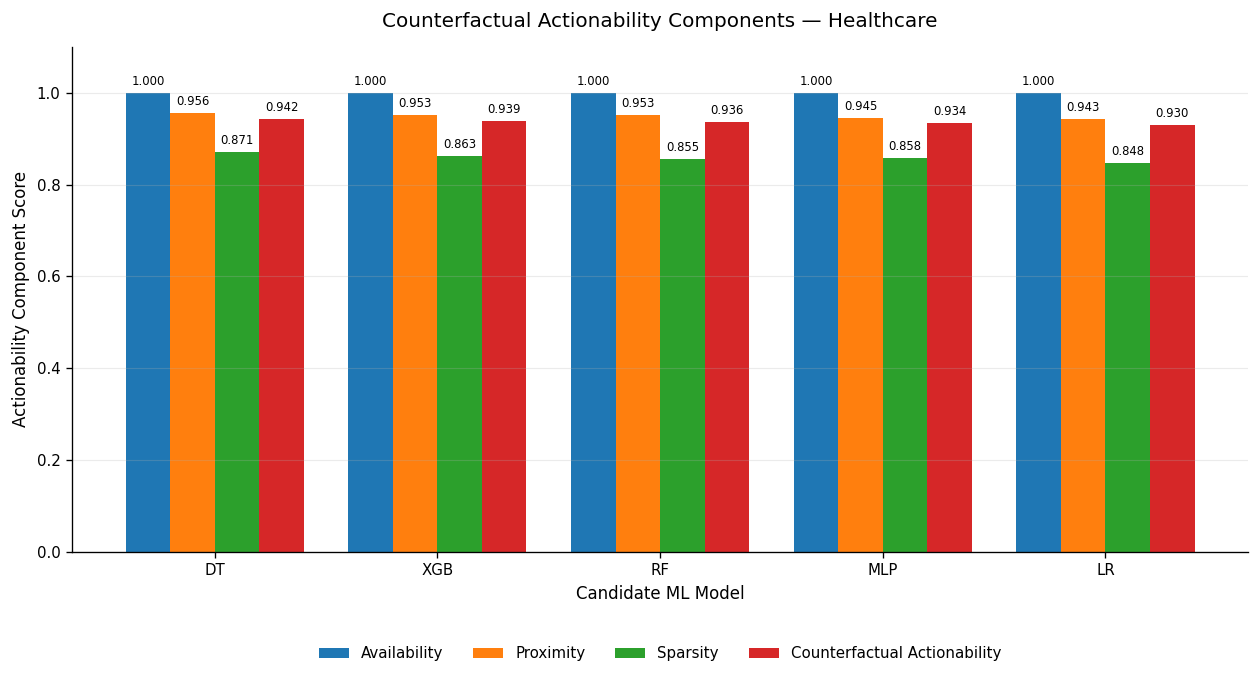

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Healthcare_Counterfactual_Actionability.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Healthcare_Counterfactual_Actionability.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Healthcare_Counterfactual_Actionability.svg


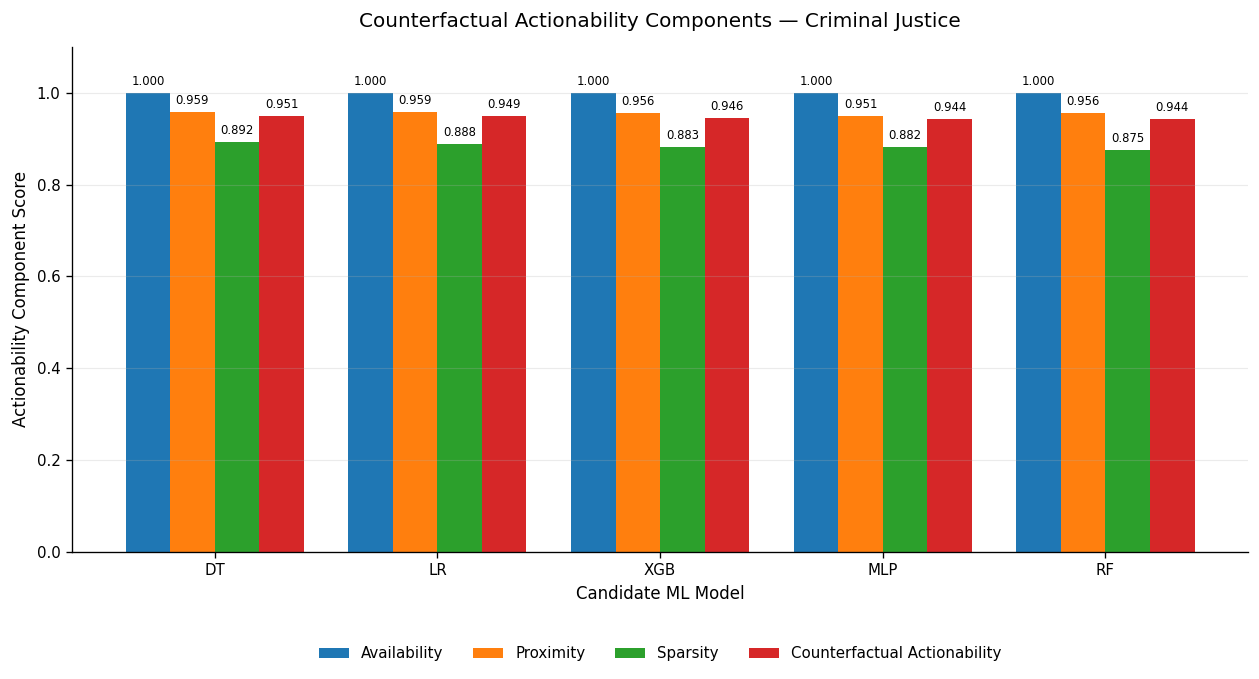

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Criminal_Justice_Counterfactual_Actionability.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Criminal_Justice_Counterfactual_Actionability.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_D_Criminal_Justice_Counterfactual_Actionability.svg


In [7]:

# ============================================================
# 7. COUNTERFACTUAL ACTIONABILITY FIGURES
# Tables 4.11–4.13
# ============================================================

actionability_components = [
    c for c in [
        "availability_score",
        "proximity_score",
        "sparsity_score",
        "actionability_score",
    ]
    if c in actionability_df.columns
]
actionability_rank_col = find_first_column(actionability_df, ["actionability_rank", "rank"])

table_map = {
    "Credit Risk": "Table 4.11",
    "Healthcare": "Table 4.12",
    "Criminal Justice": "Table 4.13",
}

for domain in ordered_domains(actionability_df["dataset_label"].dropna().unique()):
    plot_grouped_components_by_domain(
        actionability_df,
        domain,
        actionability_components,
        title=f"Counterfactual Actionability Components — {domain}",
        ylabel="Actionability Component Score",
        stem=f"Figure_D_{safe_slug(domain)}_Counterfactual_Actionability",
        chapter_table=table_map.get(domain, ""),
        caption=f"Counterfactual Actionability dimension results for the {domain} validation domain.",
        rank_col=actionability_rank_col,
        upper=1.10,
    )



## Figure group E — Regulatory Alignment dimension

These figures provide visual alternatives for Tables 4.14–4.16.  
A heatmap is used because the Regulatory Alignment dimension contains seven criteria; this presents the full evidence more clearly than a dense grouped bar chart.


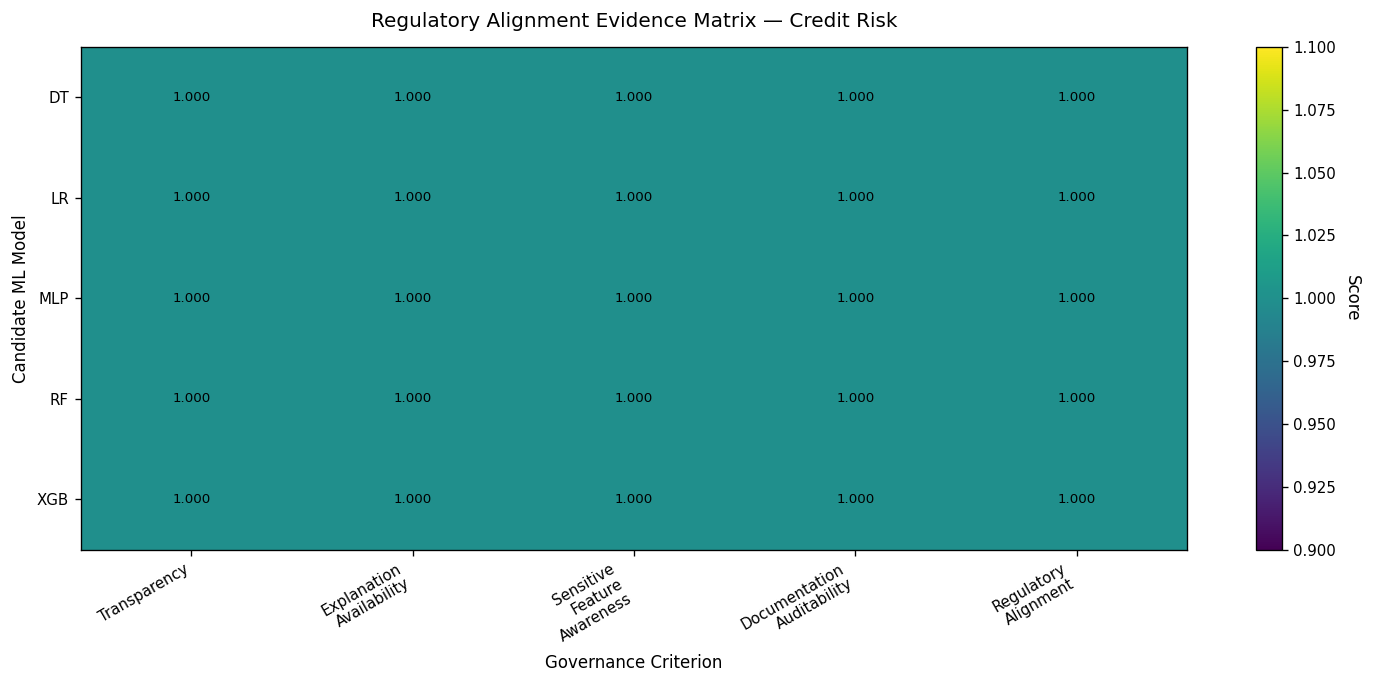

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Credit_Risk_Regulatory_Alignment.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Credit_Risk_Regulatory_Alignment.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Credit_Risk_Regulatory_Alignment.svg


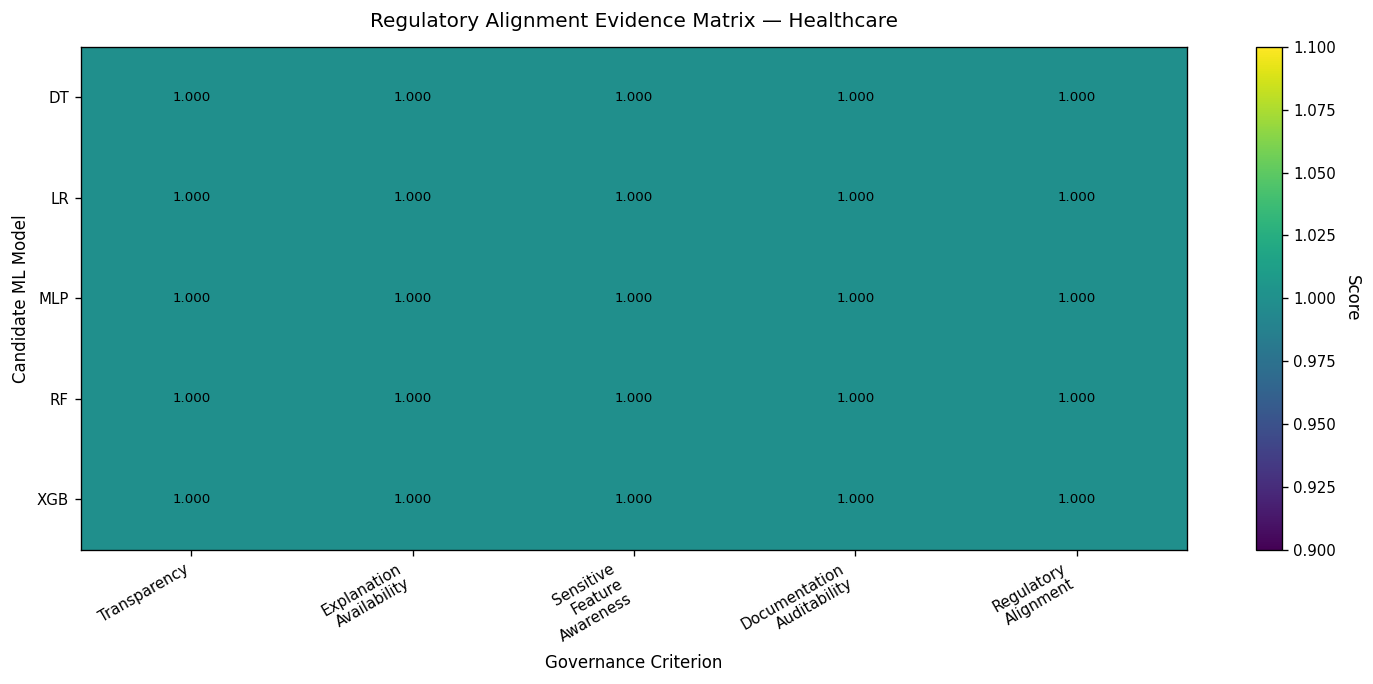

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Healthcare_Regulatory_Alignment.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Healthcare_Regulatory_Alignment.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Healthcare_Regulatory_Alignment.svg


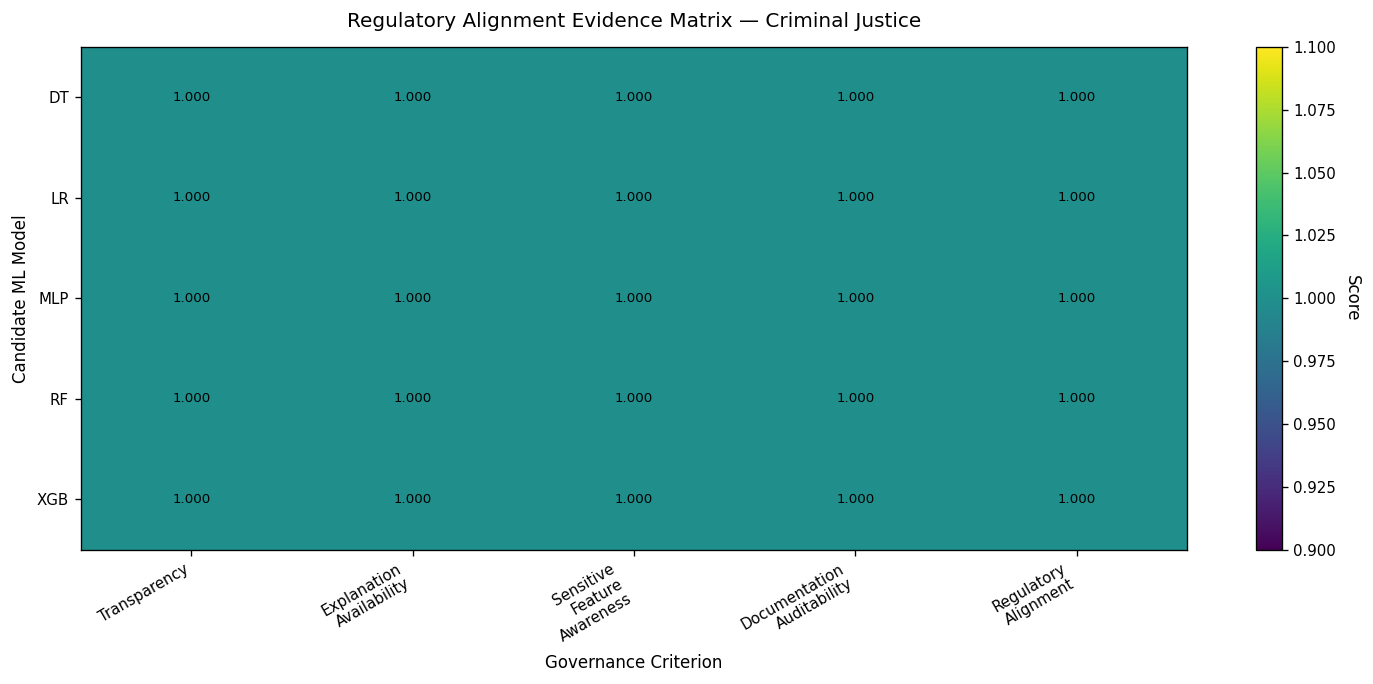

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Criminal_Justice_Regulatory_Alignment.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Criminal_Justice_Regulatory_Alignment.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_E_Criminal_Justice_Regulatory_Alignment.svg


In [8]:

# ============================================================
# 8. REGULATORY ALIGNMENT FIGURES
# Tables 4.14–4.16
# ============================================================

regulatory_components = [
    c for c in [
        "transparency_score",
        "explanation_availability_score",
        "fidelity_alignment_score",
        "stability_alignment_score",
        "actionability_contestability_score",
        "sensitive_feature_awareness_score",
        "documentation_auditability_score",
        "regulatory_alignment_score",
    ]
    if c in regulatory_df.columns
]
regulatory_rank_col = find_first_column(
    regulatory_df,
    ["regulatory_alignment_rank", "rank"]
)

table_map = {
    "Credit Risk": "Table 4.14",
    "Healthcare": "Table 4.15",
    "Criminal Justice": "Table 4.16",
}

for domain in ordered_domains(regulatory_df["dataset_label"].dropna().unique()):
    sub = domain_subset(regulatory_df, domain)
    if sub.empty:
        continue

    if regulatory_rank_col and regulatory_rank_col in sub.columns:
        sub = sub.sort_values(regulatory_rank_col)
    else:
        sub = sub.sort_values("regulatory_alignment_score", ascending=False)

    matrix = sub.set_index("model_name")[regulatory_components].copy()
    matrix.columns = [
        DIMENSION_LABELS.get(
            c,
            c.replace("_score", "").replace("_", " ").title()
        )
        for c in matrix.columns
    ]

    plot_heatmap(
        matrix,
        title=f"Regulatory Alignment Evidence Matrix — {domain}",
        stem=f"Figure_E_{safe_slug(domain)}_Regulatory_Alignment",
        chapter_table=table_map.get(domain, ""),
        caption=f"Regulatory Alignment dimension results for the {domain} validation domain.",
        figsize=(12.4, 5.8),
        xlabel="Governance Criterion",
        ylabel="Candidate ML Model",
    )



## Figure group F — Overall EES Framework evaluation

These figures provide visual alternatives for Tables 4.17–4.19.  
Each domain figure shows all four EES dimensions together with the composite EES, allowing the reader to see both the final ranking and the evidence driving it.


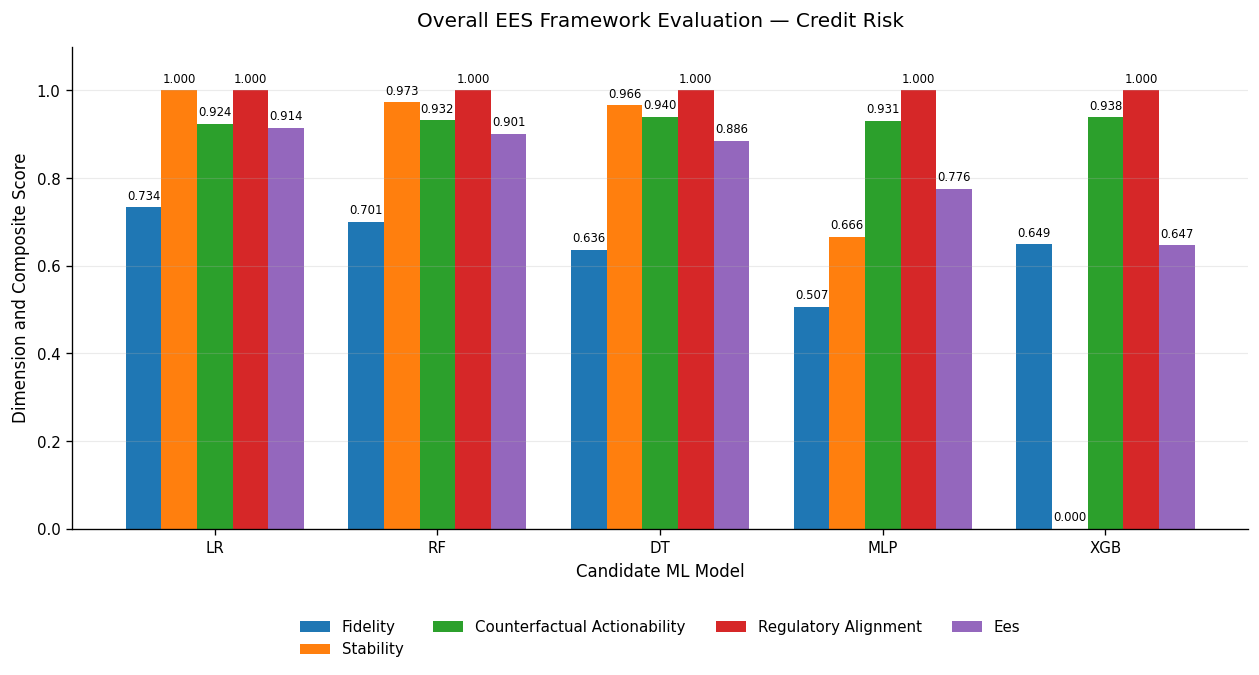

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Credit_Risk_Overall_EES_Framework.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Credit_Risk_Overall_EES_Framework.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Credit_Risk_Overall_EES_Framework.svg


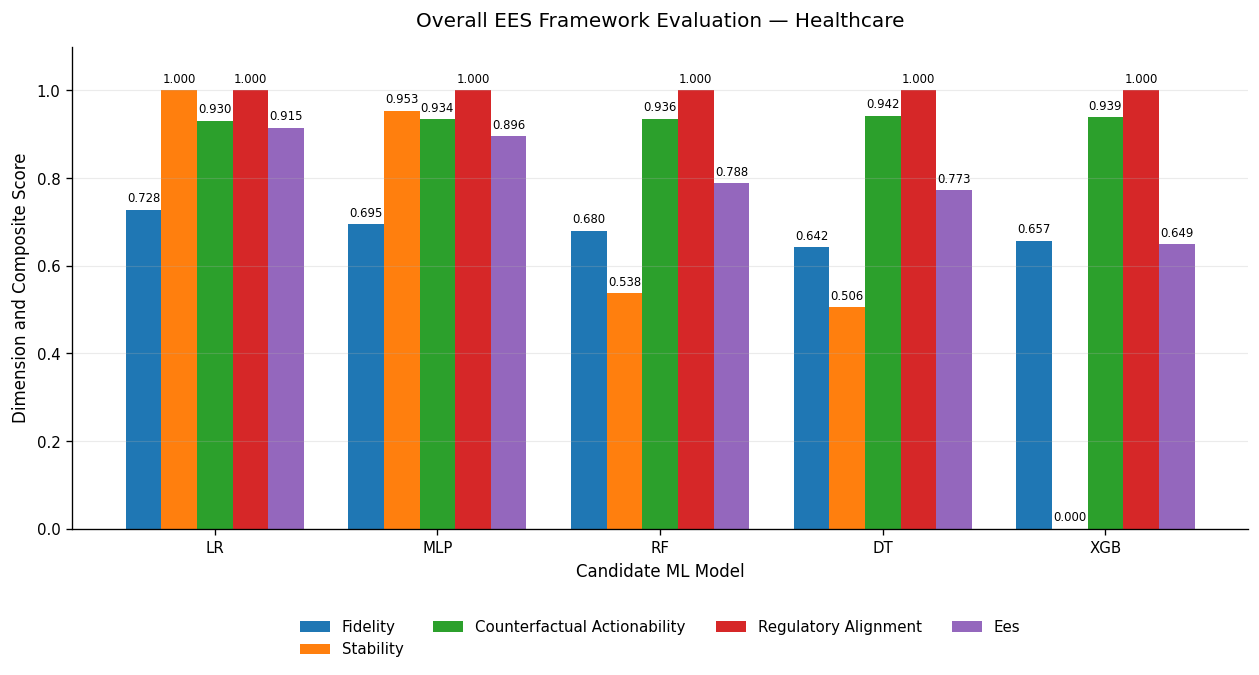

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Healthcare_Overall_EES_Framework.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Healthcare_Overall_EES_Framework.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Healthcare_Overall_EES_Framework.svg


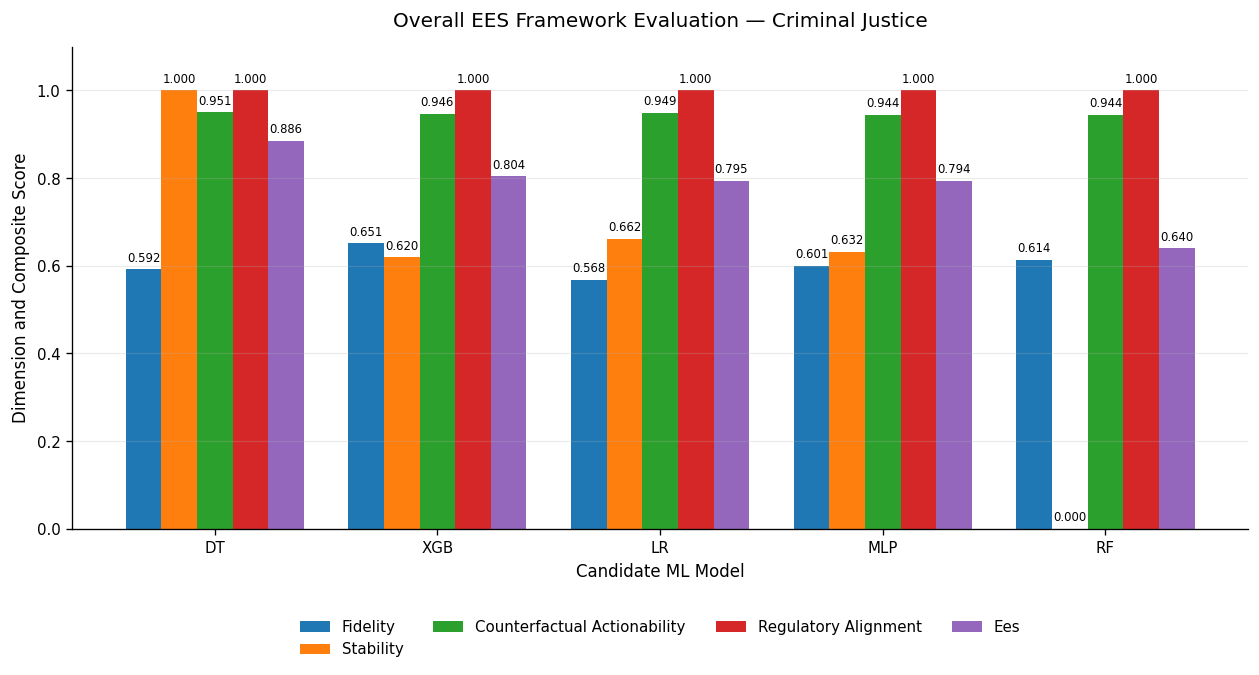

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Criminal_Justice_Overall_EES_Framework.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Criminal_Justice_Overall_EES_Framework.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_F_Criminal_Justice_Overall_EES_Framework.svg


In [9]:

# ============================================================
# 9. OVERALL EES FIGURES
# Tables 4.17–4.19
# ============================================================

ees_components = [
    c for c in [
        "fidelity_score",
        "stability_score",
        "actionability_score",
        "regulatory_alignment_score",
        "ees_score",
    ]
    if c in ees_df.columns
]
ees_rank_col = find_first_column(ees_df, ["ees_rank", "rank"])

table_map = {
    "Credit Risk": "Table 4.17",
    "Healthcare": "Table 4.18",
    "Criminal Justice": "Table 4.19",
}

for domain in ordered_domains(ees_df["dataset_label"].dropna().unique()):
    plot_grouped_components_by_domain(
        ees_df,
        domain,
        ees_components,
        title=f"Overall EES Framework Evaluation — {domain}",
        ylabel="Dimension and Composite Score",
        stem=f"Figure_F_{safe_slug(domain)}_Overall_EES_Framework",
        chapter_table=table_map.get(domain, ""),
        caption=f"Overall EES Framework evaluation for the {domain} validation domain.",
        rank_col=ees_rank_col,
        upper=1.10,
    )



## Figure group G — Predictive champion versus EES champion

This figure is the visual alternative for Table 4.20 and directly communicates the study's central result: the model selected under predictive performance differs from the model selected under the EES Framework.


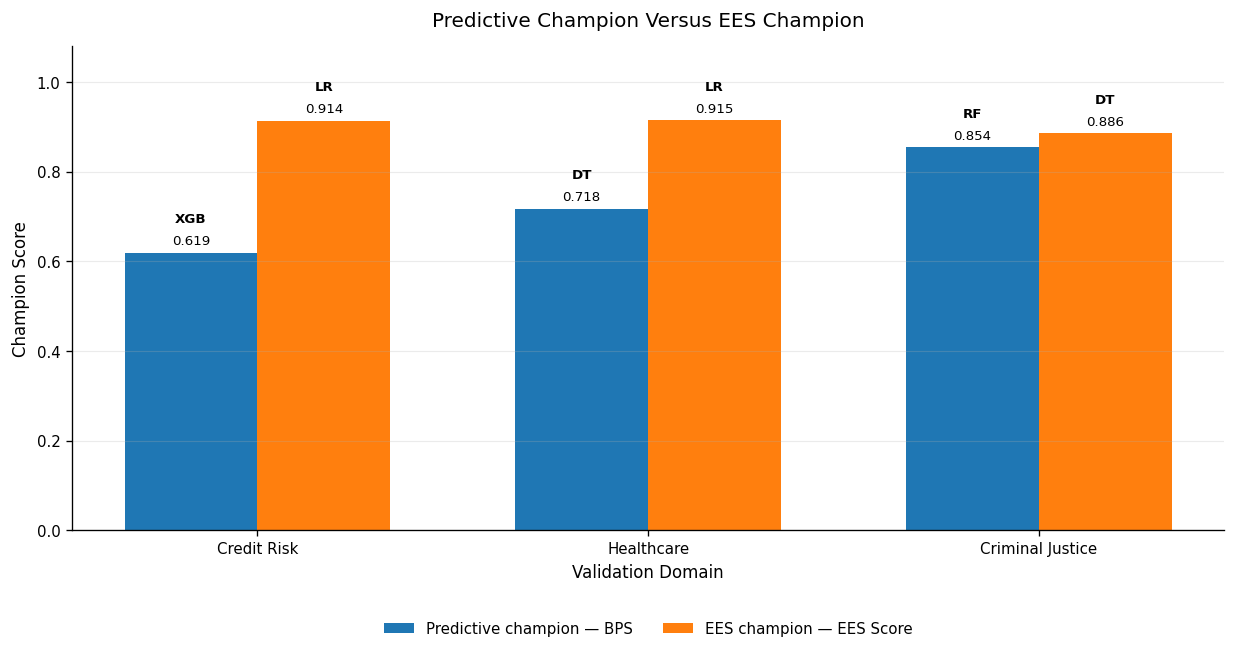

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_G_Predictive_Champion_vs_EES_Champion.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_G_Predictive_Champion_vs_EES_Champion.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_G_Predictive_Champion_vs_EES_Champion.svg


### Predictive and EES champion comparison

,dataset_label,predictive_champion,predictive_score,ees_champion,ees_score,decision_changed
0,Credit Risk,XGB,0.619293,LR,0.914286,True
1,Healthcare,DT,0.717647,LR,0.914646,True
2,Criminal Justice,RF,0.854279,DT,0.885577,True


In [10]:

# ============================================================
# 10. PREDICTIVE VS EES MODEL-SELECTION OUTCOMES
# Table 4.20
# ============================================================

if baseline_rank_col:
    predictive_champions = (
        baseline_df.sort_values(["dataset_label", baseline_rank_col])
        .groupby("dataset_label", as_index=False)
        .first()[["dataset_label", "model_name", "business_priority_score"]]
        .rename(columns={
            "model_name": "predictive_champion",
            "business_priority_score": "predictive_score",
        })
    )
else:
    predictive_champions = (
        baseline_df.sort_values(["dataset_label", "business_priority_score"], ascending=[True, False])
        .groupby("dataset_label", as_index=False)
        .first()[["dataset_label", "model_name", "business_priority_score"]]
        .rename(columns={
            "model_name": "predictive_champion",
            "business_priority_score": "predictive_score",
        })
    )

if ees_rank_col:
    ees_champions = (
        ees_df.sort_values(["dataset_label", ees_rank_col])
        .groupby("dataset_label", as_index=False)
        .first()[["dataset_label", "model_name", "ees_score"]]
        .rename(columns={
            "model_name": "ees_champion",
            "ees_score": "ees_score",
        })
    )
else:
    ees_champions = (
        ees_df.sort_values(["dataset_label", "ees_score"], ascending=[True, False])
        .groupby("dataset_label", as_index=False)
        .first()[["dataset_label", "model_name", "ees_score"]]
        .rename(columns={
            "model_name": "ees_champion",
            "ees_score": "ees_score",
        })
    )

comparison = predictive_champions.merge(ees_champions, on="dataset_label", how="inner")
comparison["decision_changed"] = comparison["predictive_champion"] != comparison["ees_champion"]

fig, ax = plt.subplots(figsize=(10.4, 5.6))
domains = ordered_domains(comparison["dataset_label"])
comparison["dataset_label"] = pd.Categorical(
    comparison["dataset_label"],
    categories=domains,
    ordered=True,
)
comparison = comparison.sort_values("dataset_label").reset_index(drop=True)

x = np.arange(len(comparison))
width = 0.34
ax.bar(x - width/2, comparison["predictive_score"], width=width, label="Predictive champion — BPS")
ax.bar(x + width/2, comparison["ees_score"], width=width, label="EES champion — EES Score")

ax.set_xticks(x)
ax.set_xticklabels(comparison["dataset_label"])
ax.set_ylabel("Champion Score")
ax.set_xlabel("Validation Domain")
ax.set_title("Predictive Champion Versus EES Champion", pad=12)
ax.set_ylim(0, 1.08)
style_axes(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
add_value_labels(ax, decimals=3)

for idx, row in comparison.iterrows():
    ax.annotate(
        abbreviate_model_name(row["predictive_champion"]),
        (idx - width/2, row["predictive_score"]),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold",
    )
    ax.annotate(
        abbreviate_model_name(row["ees_champion"]),
        (idx + width/2, row["ees_score"]),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold",
    )

fig.tight_layout()
save_figure(
    fig,
    "Figure_G_Predictive_Champion_vs_EES_Champion",
    "Table 4.20",
    "Comparison of predictive and EES model-selection outcomes across the three validation domains.",
)

display(Markdown("### Predictive and EES champion comparison"))

comparison_display = comparison.copy()
comparison_display["predictive_champion"] = comparison_display["predictive_champion"].map(abbreviate_model_name)
comparison_display["ees_champion"] = comparison_display["ees_champion"].map(abbreviate_model_name)

display(comparison_display)



## Figure group H — Robustness and sensitivity analysis

The notebook produces:
1. a weighting-scheme profile corresponding to Table 4.21;
2. an AHP consistency figure corresponding to Table 4.22; and
3. a ranking-robustness figure when the relevant Notebook 09 output is available.


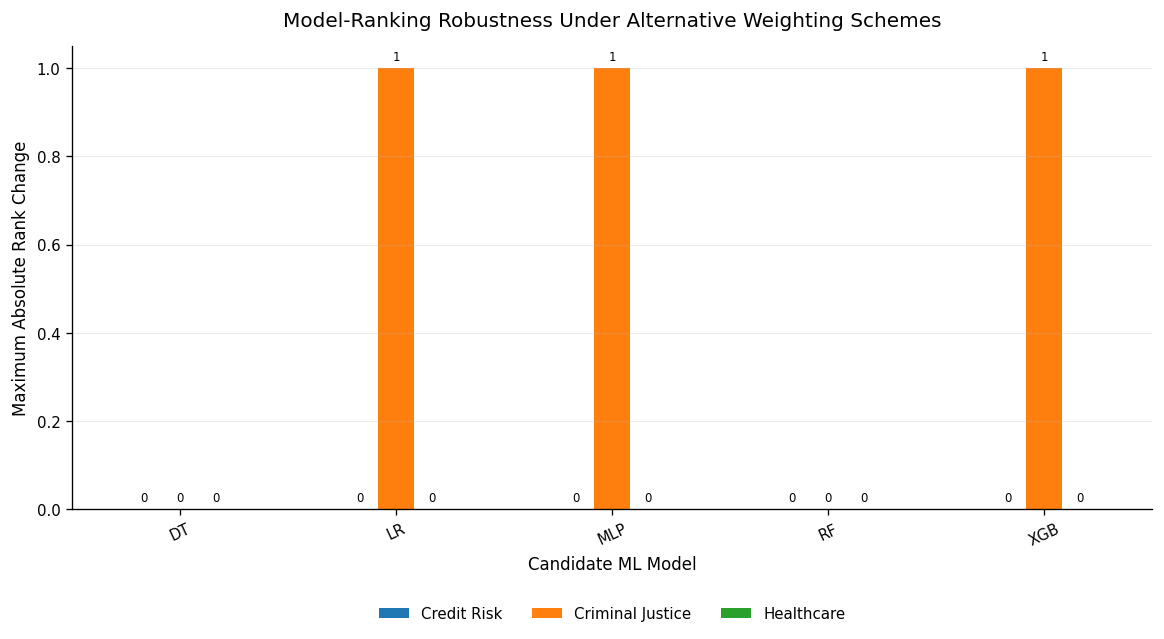

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_H3_AHP_Ranking_Robustness.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_H3_AHP_Ranking_Robustness.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_H3_AHP_Ranking_Robustness.svg


In [11]:

# ============================================================
# 11. ROBUSTNESS AND SENSITIVITY FIGURES
# Tables 4.21–4.22
# ============================================================

# 11A. Weighting schemes
weight_cols = [
    c for c in [
        "fidelity_weight",
        "stability_weight",
        "actionability_weight",
        "regulatory_alignment_weight",
        "fidelity",
        "stability",
        "actionability",
        "regulatory_alignment",
    ]
    if c in ahp_df.columns
]

scheme_col = find_first_column(ahp_df, ["scheme_name", "scheme_id", "scheme"])
if not ahp_df.empty and scheme_col and weight_cols:
    # Remove duplicates across domains where the same scheme weights repeat.
    weights = ahp_df[[scheme_col] + weight_cols].drop_duplicates().copy()

    # Prefer the first four valid weight columns.
    preferred = []
    for logical_name, candidates in {
        "Fidelity": ["fidelity_weight", "fidelity"],
        "Stability": ["stability_weight", "stability"],
        "Counterfactual Actionability": ["actionability_weight", "actionability"],
        "Regulatory Alignment": ["regulatory_alignment_weight", "regulatory_alignment"],
    }.items():
        col = next((c for c in candidates if c in weights.columns), None)
        if col:
            preferred.append((logical_name, col))

    if preferred:
        x = np.arange(len(weights))
        bottom = np.zeros(len(weights))
        fig, ax = plt.subplots(figsize=(11.0, 5.8))
        for label, col in preferred:
            values = pd.to_numeric(weights[col], errors="coerce").fillna(0).values
            ax.bar(x, values, bottom=bottom, label=label)
            bottom += values

        ax.set_xticks(x)
        ax.set_xticklabels(wrap_labels(weights[scheme_col], 18), rotation=20, ha="right")
        ax.set_ylabel("Dimension Weight")
        ax.set_xlabel("AHP Weighting Scheme")
        ax.set_title("Weighting Schemes Used for Robustness and Sensitivity Analysis", pad=12)
        ax.set_ylim(0, max(1.0, float(np.nanmax(bottom)) * 1.05))
        style_axes(ax)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False)
        fig.tight_layout()
        save_figure(
            fig,
            "Figure_H1_AHP_Weighting_Schemes",
            "Table 4.21",
            "Weighting schemes used for robustness and sensitivity analysis.",
        )

# 11B. AHP consistency diagnostics
cr_col = find_first_column(ahp_df, ["consistency_ratio", "cr"])
if not ahp_df.empty and cr_col and scheme_col:
    plot_df = ahp_df.copy()
    hue_col = "dataset_label" if "dataset_label" in plot_df.columns else None

    if hue_col:
        pivot = plot_df.pivot_table(
            index=scheme_col,
            columns=hue_col,
            values=cr_col,
            aggfunc="mean"
        )
        fig, ax = plt.subplots(figsize=(11.0, 5.6))
        pivot.plot(kind="bar", ax=ax)
        ax.axhline(0.10, linestyle="--", linewidth=1.2, label="Consistency threshold = 0.10")
        ax.set_ylabel("Consistency Ratio")
        ax.set_xlabel("AHP Weighting Scheme")
        ax.set_title("AHP Consistency Diagnostics Across Validation Domains", pad=12)
        ax.tick_params(axis="x", rotation=25)
        style_axes(ax)
        add_value_labels(ax, decimals=3, fontsize=7)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
        fig.tight_layout()
    else:
        fig, ax = plt.subplots(figsize=(9.0, 5.2))
        ax.bar(plot_df[scheme_col], plot_df[cr_col])
        ax.axhline(0.10, linestyle="--", linewidth=1.2, label="Consistency threshold = 0.10")
        ax.set_ylabel("Consistency Ratio")
        ax.set_xlabel("AHP Weighting Scheme")
        ax.set_title("AHP Consistency Diagnostics", pad=12)
        ax.tick_params(axis="x", rotation=25)
        style_axes(ax)
        add_value_labels(ax, decimals=3)
        ax.legend(frameon=False)
        fig.tight_layout()

    save_figure(
        fig,
        "Figure_H2_AHP_Consistency_Diagnostics",
        "Table 4.22",
        "AHP consistency diagnostics across the three validation domains.",
    )

# 11C. Ranking robustness
if not robustness_df.empty:
    rank_change_col = find_first_column(
        robustness_df,
        [
            "max_rank_change_vs_equal_weight",
            "rank_change_vs_equal_weight",
            "absolute_rank_change",
            "rank_change",
        ]
    )
    if rank_change_col and "model_name" in robustness_df.columns:
        group_cols = ["model_name"]
        if "dataset_label" in robustness_df.columns:
            group_cols.insert(0, "dataset_label")

        robustness_summary = (
            robustness_df.groupby(group_cols, as_index=False)[rank_change_col]
            .max()
        )

        if "dataset_label" in robustness_summary.columns:
            pivot = robustness_summary.pivot(
                index="model_name",
                columns="dataset_label",
                values=rank_change_col,
            )
            fig, ax = plt.subplots(figsize=(9.8, 5.5))
            pivot.index = [abbreviate_model_name(v) for v in pivot.index]
            pivot.plot(kind="bar", ax=ax)
            ax.set_ylabel("Maximum Absolute Rank Change")
            ax.set_xlabel("Candidate ML Model")
            ax.set_title("Model-Ranking Robustness Under Alternative Weighting Schemes", pad=12)
            ax.tick_params(axis="x", rotation=25)
            style_axes(ax)
            add_value_labels(ax, decimals=0, fontsize=7)
            ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
            fig.tight_layout()
        else:
            fig, ax = plt.subplots(figsize=(8.8, 5.0))
            ax.bar(abbreviate_model_labels(robustness_summary["model_name"]), robustness_summary[rank_change_col])
            ax.set_ylabel("Maximum Absolute Rank Change")
            ax.set_xlabel("Candidate ML Model")
            ax.set_title("Model-Ranking Robustness Under Alternative Weighting Schemes", pad=12)
            ax.tick_params(axis="x", rotation=25)
            style_axes(ax)
            add_value_labels(ax, decimals=0)
            fig.tight_layout()

        save_figure(
            fig,
            "Figure_H3_AHP_Ranking_Robustness",
            "Supplementary to Tables 4.21–4.22",
            "Maximum model-rank changes under alternative AHP weighting schemes.",
        )



## Figure group I — Cross-domain empirical synthesis

This final figure supports Table 4.23 and Section 4.9.  
It summarises the average EES profile across domains and shows which models provide the strongest cross-domain balance.


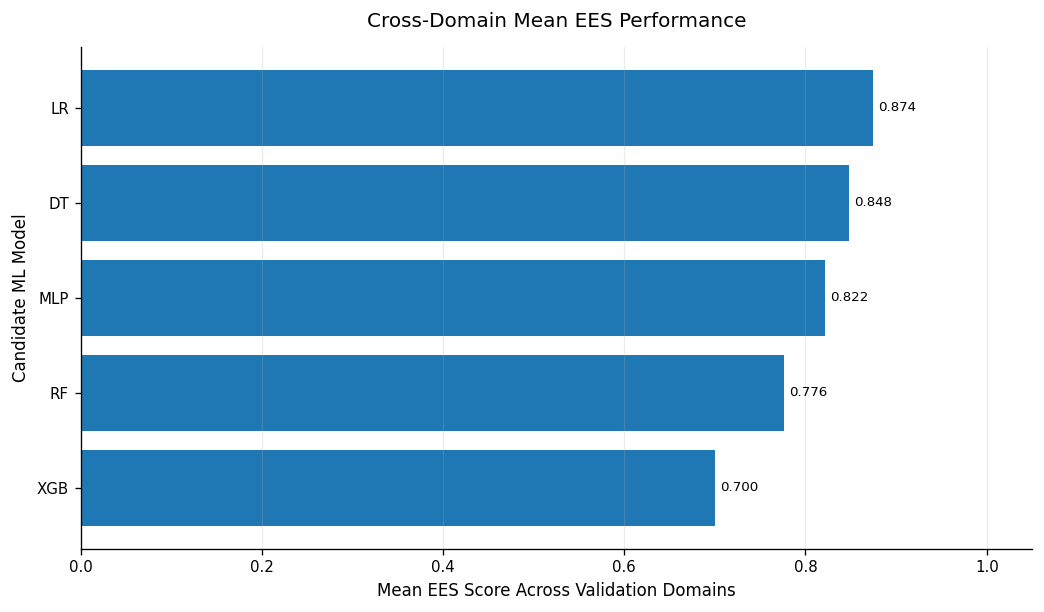

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I1_Cross_Domain_Mean_EES.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I1_Cross_Domain_Mean_EES.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I1_Cross_Domain_Mean_EES.svg


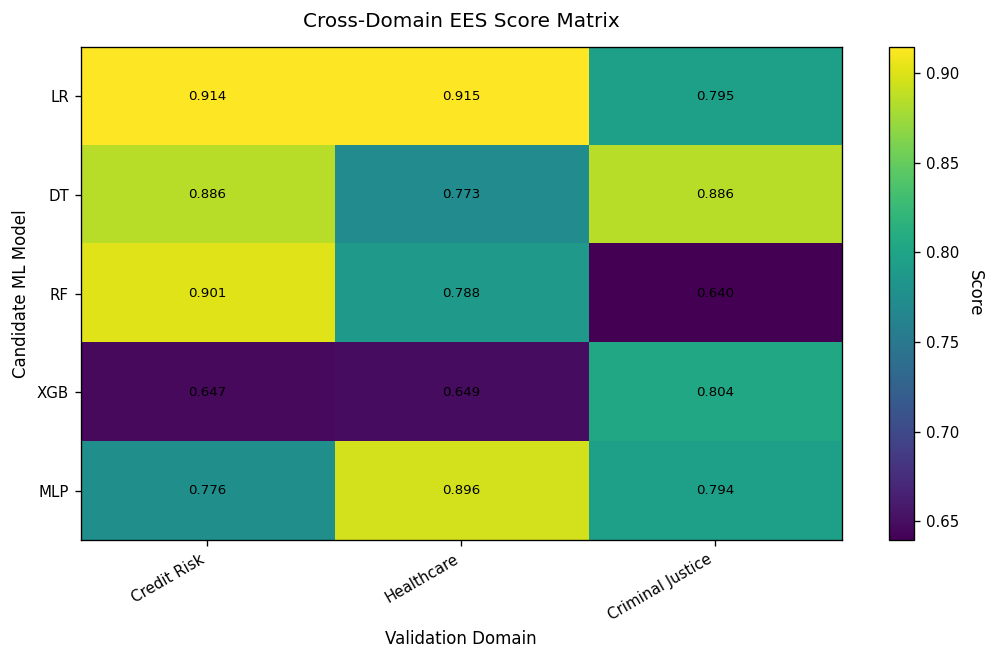

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I2_Cross_Domain_EES_Matrix.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I2_Cross_Domain_EES_Matrix.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I2_Cross_Domain_EES_Matrix.svg


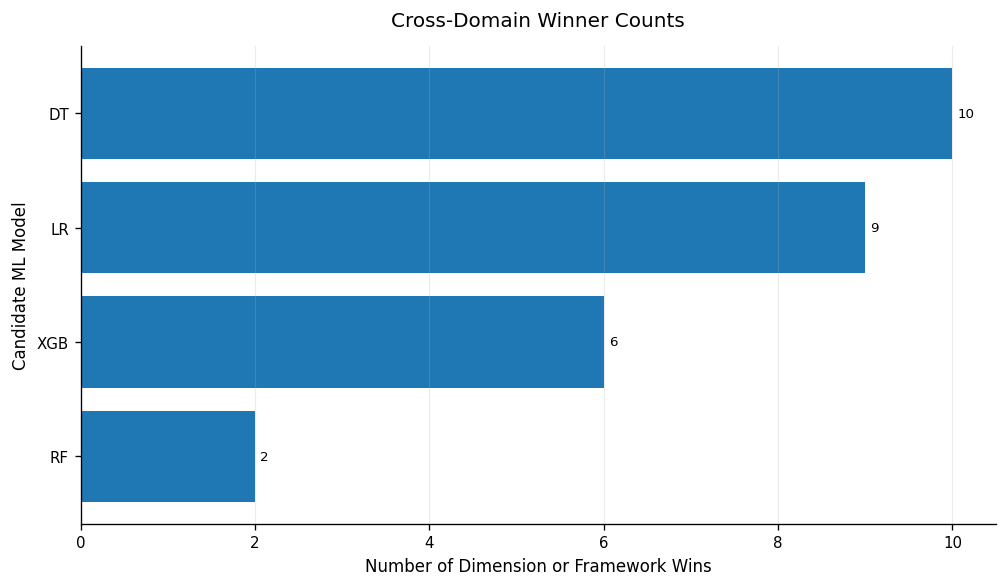

Saved: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I3_Cross_Domain_Winner_Counts.png, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I3_Cross_Domain_Winner_Counts.pdf, /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures/Figure_I3_Cross_Domain_Winner_Counts.svg


In [12]:

# ============================================================
# 12. CROSS-DOMAIN EMPIRICAL SYNTHESIS
# Table 4.23
# ============================================================

# Prefer a direct cross-dataset average table when available.
if not average_ees_df.empty and "model_name" in average_ees_df.columns:
    mean_col = find_first_column(
        average_ees_df,
        ["mean_ees_score", "average_ees_score", "ees_score"]
    )
    rank_col = find_first_column(
        average_ees_df,
        ["cross_dataset_ees_rank", "ees_rank", "rank"]
    )

    if mean_col:
        plot_df = average_ees_df.copy()
        if rank_col:
            plot_df = plot_df.sort_values(rank_col)
        else:
            plot_df = plot_df.sort_values(mean_col, ascending=False)

        fig, ax = plt.subplots(figsize=(8.8, 5.2))
        ax.barh(abbreviate_model_labels(plot_df["model_name"]), plot_df[mean_col])
        ax.invert_yaxis()
        ax.set_xlabel("Mean EES Score Across Validation Domains")
        ax.set_ylabel("Candidate ML Model")
        ax.set_title("Cross-Domain Mean EES Performance", pad=12)
        ax.set_xlim(0, 1.05)
        style_axes(ax, grid_axis="x")
        add_value_labels(ax, decimals=3, horizontal=True)
        fig.tight_layout()
        save_figure(
            fig,
            "Figure_I1_Cross_Domain_Mean_EES",
            "Table 4.23",
            "Cross-domain mean EES performance of the candidate ML models.",
        )

# Cross-domain EES matrix: model × domain
if {"dataset_label", "model_name", "ees_score"}.issubset(ees_df.columns):
    matrix = ees_df.pivot_table(
        index="model_name",
        columns="dataset_label",
        values="ees_score",
        aggfunc="mean",
    )
    matrix = matrix.reindex(
        index=[m for m in MODEL_ORDER if m in matrix.index],
        columns=[d for d in DOMAIN_ORDER if d in matrix.columns],
    )

    plot_heatmap(
        matrix,
        title="Cross-Domain EES Score Matrix",
        stem="Figure_I2_Cross_Domain_EES_Matrix",
        chapter_table="Table 4.23",
        caption="Cross-domain synthesis of EES Framework outcomes.",
        figsize=(8.8, 5.6),
        xlabel="Validation Domain",
        ylabel="Candidate ML Model",
    )

# Optional winner-count synthesis
if not winner_matrix_df.empty:
    id_col = "section" if "section" in winner_matrix_df.columns else winner_matrix_df.columns[0]
    long_df = winner_matrix_df.melt(
        id_vars=[id_col],
        var_name="dataset_label",
        value_name="winner_model_name",
    )
    winner_counts = (
        long_df.dropna(subset=["winner_model_name"])
        .groupby("winner_model_name", as_index=False)
        .size()
        .rename(columns={"size": "number_of_wins"})
        .sort_values("number_of_wins", ascending=False)
    )

    if not winner_counts.empty:
        fig, ax = plt.subplots(figsize=(8.5, 5.0))
        ax.barh(abbreviate_model_labels(winner_counts["winner_model_name"]), winner_counts["number_of_wins"])
        ax.invert_yaxis()
        ax.set_xlabel("Number of Dimension or Framework Wins")
        ax.set_ylabel("Candidate ML Model")
        ax.set_title("Cross-Domain Winner Counts", pad=12)
        style_axes(ax, grid_axis="x")
        add_value_labels(ax, decimals=0, horizontal=True)
        fig.tight_layout()
        save_figure(
            fig,
            "Figure_I3_Cross_Domain_Winner_Counts",
            "Supplementary to Table 4.23",
            "Cross-domain counts of model wins across evaluation dimensions.",
        )


In [13]:

# ============================================================
# 13. EXPORT FIGURE MANIFEST
# ============================================================

manifest_df = pd.DataFrame(FIGURE_MANIFEST)
manifest_df.to_csv(MANIFEST_PATH, index=False)

display(Markdown("## Figure output manifest"))
display(manifest_df)

print("=" * 100)
print("Notebook 11 completed successfully.")
print(f"Figures saved to : {FIGURES_PATH}")
print(f"Manifest saved to: {MANIFEST_PATH}")
print("=" * 100)


## Figure output manifest

,figure_file_stem,corresponding_dissertation_table,suggested_caption,saved_formats
0,Figure_A_Credit_Risk_Baseline_Predictive_Perfo...,Table 4.1,"Recall, ROC-AUC, Precision, and the resulting ...","PNG, PDF, SVG"
1,Figure_A_Healthcare_Baseline_Predictive_Perfor...,Table 4.2,"Recall, ROC-AUC, Precision, and the resulting ...","PNG, PDF, SVG"
2,Figure_A_Criminal_Justice_Baseline_Predictive_...,Table 4.3,"Recall, ROC-AUC, Precision, and the resulting ...","PNG, PDF, SVG"
3,Figure_A_Summary_Predictive_Champions,Table 4.4,Summary of BPS predictive champions across the...,"PNG, PDF, SVG"
4,Figure_B_Credit_Risk_Fidelity_Dimension,Table 4.5,Fidelity dimension components for the Credit R...,"PNG, PDF, SVG"
5,Figure_B_Healthcare_Fidelity_Dimension,Table 4.6,Fidelity dimension components for the Healthca...,"PNG, PDF, SVG"
6,Figure_B_Criminal_Justice_Fidelity_Dimension,Table 4.7,Fidelity dimension components for the Criminal...,"PNG, PDF, SVG"
7,Figure_C_Credit_Risk_Stability_Dimension,Table 4.8,Stability dimension results for the Credit Ris...,"PNG, PDF, SVG"
8,Figure_C_Healthcare_Stability_Dimension,Table 4.9,Stability dimension results for the Healthcare...,"PNG, PDF, SVG"
9,Figure_C_Criminal_Justice_Stability_Dimension,Table 4.10,Stability dimension results for the Criminal J...,"PNG, PDF, SVG"


Notebook 11 completed successfully.
Figures saved to : /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figures
Manifest saved to: /content/drive/MyDrive/Master_Research/07_Results/11_all_figures_output_framework_validation/publication_outputs/figure_manifest.csv



## Recommended dissertation use

This notebook intentionally produces more visual outputs than should necessarily appear in the final dissertation.

A strong Chapter 4 balance would normally be:

- retain compact tables where exact values are necessary;
- use domain-level figures for the most important comparisons;
- prioritise figures that expose ranking reversals, model trade-offs, and cross-domain patterns;
- avoid presenting both a full table and a near-identical figure unless each serves a distinct purpose.

Suggested priority figures:

1. Baseline predictive performance by domain.
2. Stability by domain.
3. Overall EES by domain.
4. Predictive champion versus EES champion.
5. AHP ranking robustness.
6. Cross-domain EES matrix.

The remaining generated figures can be used selectively or moved to an appendix.
